# T02 — Interpolation manual check

Scope (per `tasks.md` T02 and the 2026-09-22 task instructions):

- hand-computable synthetic examples for `bilinear_spatial_interpolate` (ascending and
  descending latitude) and `linear_temporal_interpolate` (hourly -> 15-minute);
- missing/invalid-cell and out-of-domain behaviour, shown explicitly rather than
  silently producing a number;
- the composed `interpolate_field` query against a tiny synthetic dataset;
- the same functions run against the real `data/ocean.nc` / `data/wind.nc`, including a
  visual comparison of the raw grid vs. a finer interpolated grid;
- `NetCDFEnvironmentalFieldProvider.U`, confirming it reproduces the locked T01.5
  definition `U(x,t) = (uo(x,t), vo(x,t))`.

No particle propagation, `grad(K)`/`div(U)`, particle weights, boundary policy, forcing
ensemble, KDE, likelihood, SMC, MCMC, or AIS is implemented or exercised here.

In [1]:
import os
import sys

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt

from iste.environment import (
    GriddedFieldSource,
    NetCDFEnvironmentalFieldProvider,
    load_field_dataset,
)
from iste.interpolation import (
    bilinear_spatial_interpolate,
    interpolate_field,
    linear_temporal_interpolate,
)

OCEAN_PATH = os.path.join(REPO_ROOT, "data", "ocean.nc")
WIND_PATH = os.path.join(REPO_ROOT, "data", "wind.nc")

## 1. Synthetic bilinear spatial interpolation (hand-computable)

```text
lat = [10, 20, 30] (ascending), lon = [100, 110]
field:  lat=10 -> [1, 2]
        lat=20 -> [3, 4]
        lat=30 -> [5, 6]
```

Query `(lat=15, lon=105)` sits exactly halfway between the four corners `{1, 2, 3, 4}`, so
the expected value is their plain average: **2.5**.

In [2]:
lat_asc = np.array([10.0, 20.0, 30.0])
lon = np.array([100.0, 110.0])
field_asc = np.array([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])

value, valid = bilinear_spatial_interpolate(lat_asc, lon, field_asc, 15.0, 105.0)
print(f"ascending-latitude grid: expected 2.5, got {value[0]}, valid={valid[0]}")

# Same physical field, described with descending latitude (like the wind grid).
lat_desc = lat_asc[::-1]
field_desc = field_asc[::-1, :]
value2, valid2 = bilinear_spatial_interpolate(lat_desc, lon, field_desc, 15.0, 105.0)
print(f"descending-latitude grid: expected 2.5, got {value2[0]}, valid={valid2[0]}")

ascending-latitude grid: expected 2.5, got 2.5, valid=True
descending-latitude grid: expected 2.5, got 2.5, valid=True


## 2. Missing-cell and out-of-domain behaviour

A query whose bracketing cells include a masked/`NaN` source value, or that falls outside
the grid extent, must come back `valid=False` with a `NaN` value -- never a silently
"valid-looking" number.

In [3]:
field_with_gap = field_asc.copy()
field_with_gap[0, 0] = np.nan  # the (lat=10, lon=100) corner

v_touches_nan, ok_touches_nan = bilinear_spatial_interpolate(lat_asc, lon, field_with_gap, 15.0, 105.0)
print(f"query touching the NaN corner:      value={v_touches_nan[0]}, valid={ok_touches_nan[0]}")

v_away_from_nan, ok_away_from_nan = bilinear_spatial_interpolate(lat_asc, lon, field_with_gap, 25.0, 105.0)
print(f"query away from the NaN corner:     value={v_away_from_nan[0]}, valid={ok_away_from_nan[0]}")

v_out, ok_out = bilinear_spatial_interpolate(lat_asc, lon, field_asc, 5.0, 105.0)
print(f"query outside the latitude range:   value={v_out[0]}, valid={ok_out[0]}")

query touching the NaN corner:      value=nan, valid=False
query away from the NaN corner:     value=4.5, valid=True
query outside the latitude range:   value=nan, valid=False


## 3. Synthetic temporal interpolation (hourly -> 15-minute)

`values = [10, 20, 30]` at `00:00, 01:00, 02:00`. Expected: `00:15 -> 12.5`,
`00:45 -> 17.5`, `01:30 -> 25.0`.

In [4]:
time_hourly = np.array(["2020-01-01T00:00", "2020-01-01T01:00", "2020-01-01T02:00"], dtype="datetime64[ns]")
values_hourly = np.array([10.0, 20.0, 30.0])

for label, expected in [("00:15", 12.5), ("00:45", 17.5), ("01:30", 25.0)]:
    q = np.datetime64(f"2020-01-01T{label}")
    v, ok = linear_temporal_interpolate(time_hourly, values_hourly, q)
    print(f"{label}: expected {expected}, got {float(v)}, valid={bool(ok)}")

v_out, ok_out = linear_temporal_interpolate(time_hourly, values_hourly, np.datetime64("2020-01-01T03:00"))
print(f"out-of-range query (03:00): value={float(v_out)}, valid={bool(ok_out)}")

00:15: expected 12.5, got 12.5, valid=True
00:45: expected 17.5, got 17.5, valid=True
01:30: expected 25.0, got 25.0, valid=True
out-of-range query (03:00): value=nan, valid=False


## 4. Composed space + time query (`interpolate_field`) on a tiny synthetic dataset

Same spatial field as above, scaled by `1x`, `2x`, `3x` at three hourly timestamps. The
spatial-only value at `(15, 105)` is `2.5` at `t=00:00` and `5.0` at `t=01:00`; halfway in
time (`00:30`) must give their average: **3.75**.

In [5]:
synthetic_source = GriddedFieldSource(
    source_path="<synthetic>",
    time_name="time",
    time=time_hourly,
    lat_name="lat",
    lat=lat_asc,
    lon_name="lon",
    lon=lon,
    data={"test_var": np.stack([field_asc * 1.0, field_asc * 2.0, field_asc * 3.0])},
    fill_threshold=1e19,
)

value, valid = interpolate_field(
    synthetic_source, "test_var", lat=15.0, lon=105.0, time=np.datetime64("2020-01-01T00:30")
)
print(f"combined space+time query: expected 3.75, got {value}, valid={valid}")

combined space+time query: expected 3.75, got 3.75, valid=True


## 5. Real data: ocean grid (ascending latitude, 149x216) and wind grid (descending latitude, 25x36)

In [6]:
ocean = load_field_dataset(OCEAN_PATH, ["uo", "vo"], time_dim="time", lat_dim="latitude", lon_dim="longitude")
wind = load_field_dataset(WIND_PATH, ["u10", "v10"], time_dim="valid_time", lat_dim="latitude", lon_dim="longitude")

print("ocean lat ascending:", ocean.lat_ascending, " | wind lat ascending:", wind.lat_ascending)

# Interior 2x2 all-finite block -> the exact midpoint must equal the plain average of its
# four corners (a real-data analogue of the hand-computed synthetic case above).
uo = ocean.data["uo"]
t_idx = i_idx = j_idx = None
for t in range(uo.shape[0]):
    finite = ~np.isnan(uo[t])
    block_ok = finite[:-1, :-1] & finite[:-1, 1:] & finite[1:, :-1] & finite[1:, 1:]
    hits = np.argwhere(block_ok)
    if hits.size:
        t_idx = t
        i_idx, j_idx = hits[0]
        break

lat_mid = float((ocean.lat[i_idx] + ocean.lat[i_idx + 1]) / 2)
lon_mid = float((ocean.lon[j_idx] + ocean.lon[j_idx + 1]) / 2)
expected = float(
    uo[t_idx, i_idx, j_idx] + uo[t_idx, i_idx, j_idx + 1] + uo[t_idx, i_idx + 1, j_idx] + uo[t_idx, i_idx + 1, j_idx + 1]
) / 4.0
value, valid = interpolate_field(ocean, "uo", lat=lat_mid, lon=lon_mid, time=ocean.time[t_idx])
print(f"ocean interior midpoint: expected {expected:.6f}, got {value:.6f}, valid={valid}")

value_w, valid_w = interpolate_field(wind, "u10", lat=wind.lat[3], lon=wind.lon[5], time=wind.time[7])
expected_w = float(wind.data["u10"][7, 3, 5])
print(f"wind exact grid point (descending lat): expected {expected_w:.6f}, got {value_w:.6f}, valid={valid_w}")

c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 

ocean lat ascending: True  | wind lat ascending: False
ocean interior midpoint: expected 0.009012, got 0.009012, valid=True
wind exact grid point (descending lat): expected 0.994263, got 0.994263, valid=True


In [7]:
# A land/masked cell must come back invalid, not silently interpolated.
nan_positions = np.argwhere(np.isnan(uo[0]))
ni, nj = nan_positions[0]
land_value, land_valid = interpolate_field(ocean, "uo", lat=ocean.lat[ni], lon=ocean.lon[nj], time=ocean.time[0])
print(f"land/masked ocean cell: value={land_value}, valid={land_valid}")

land/masked ocean cell: value=nan, valid=False


## 6. Visual check: raw ocean grid vs. finer interpolated grid

The interpolated field should look like a smooth version of the raw grid, with masked
land cells (`NaN`) still visibly blank rather than filled in.

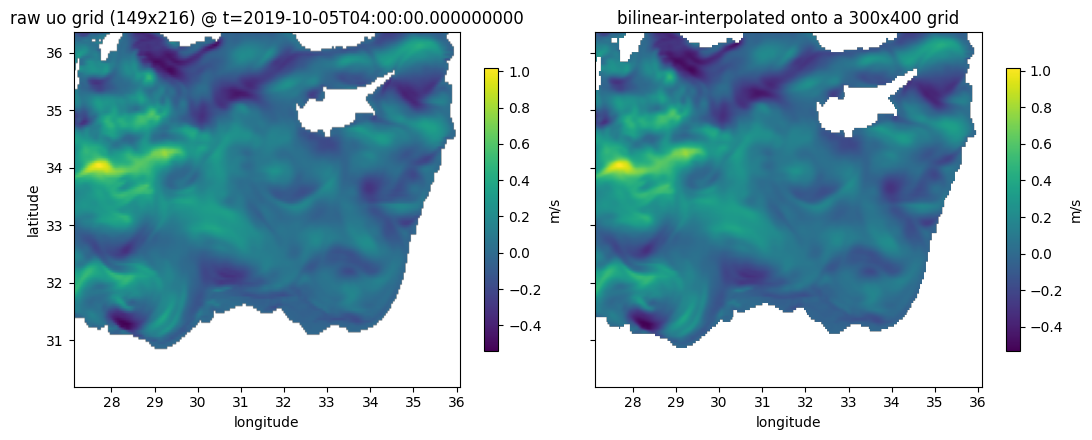

fine-grid valid fraction: 0.714 (land/out-of-domain points are invalid, not interpolated)


In [8]:
t_plot = 100
raw_slice = ocean.data["uo"][t_plot]

lat_fine = np.linspace(ocean.lat.min(), ocean.lat.max(), 300)
lon_fine = np.linspace(ocean.lon.min(), ocean.lon.max(), 400)
LON, LAT = np.meshgrid(lon_fine, lat_fine)
fine_values, fine_valid = bilinear_spatial_interpolate(ocean.lat, ocean.lon, raw_slice, LAT.ravel(), LON.ravel())
fine_grid = fine_values.reshape(LAT.shape)

extent = [ocean.lon.min(), ocean.lon.max(), ocean.lat.min(), ocean.lat.max()]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
im0 = axes[0].imshow(raw_slice, origin="lower", extent=extent, aspect="auto", cmap="viridis")
axes[0].set_title(f"raw uo grid (149x216) @ t={ocean.time[t_plot]}")
axes[0].set_xlabel("longitude"); axes[0].set_ylabel("latitude")
fig.colorbar(im0, ax=axes[0], shrink=0.8, label="m/s")

im1 = axes[1].imshow(fine_grid, origin="lower", extent=extent, aspect="auto", cmap="viridis")
axes[1].set_title("bilinear-interpolated onto a 300x400 grid")
axes[1].set_xlabel("longitude")
fig.colorbar(im1, ax=axes[1], shrink=0.8, label="m/s")
fig.tight_layout()
plt.show()

print(f"fine-grid valid fraction: {fine_valid.mean():.3f} (land/out-of-domain points are invalid, not interpolated)")

## 7. `NetCDFEnvironmentalFieldProvider.U` — wired to the locked T01.5 definition

In [9]:
provider = NetCDFEnvironmentalFieldProvider(ocean)
x = np.array([lon_mid, lat_mid])  # x = (lon, lat)
t_query = ocean.time[t_idx]
print("provider.U(x, t):", provider.U(x, t_query))
print("provider.validity(x, t):", provider.validity(x, t_query))

try:
    provider.K(x, t_query)
except NotImplementedError as exc:
    print("provider.K(...) correctly raises NotImplementedError:", exc)

provider.U(x, t): [ 0.00901181 -0.0121389 ]
provider.validity(x, t): True
provider.K(...) correctly raises NotImplementedError: K has no defined value/formula yet -- see T01.5/T03


## Summary / known limitations

- Spatial (bilinear) and temporal (linear) interpolation each match their hand-computed
  synthetic expectations, on both ascending (ocean) and descending (wind) latitude grids
  and on grids of different resolution.
- Missing/masked source cells and out-of-domain queries come back `valid=False` with a
  `NaN` value, not a silently plausible number; this is stricter than "the point itself
  looks fine" -- an exact grid vertex next to a masked neighbour is correctly marked
  invalid too, since its bracket still touches that neighbour.
- `NetCDFEnvironmentalFieldProvider.U` reproduces the T01.5-locked
  `U(x,t) = (uo(x,t), vo(x,t))` exactly; `K`, `grad_K`, `div_U` still raise
  `NotImplementedError` (T03+, and `K`'s definition remains an open decision).
- This T02 "invalid" flag is an interpolation/data-coverage signal only -- it is not the
  Stage III particle boundary/land policy (T04), and no particle propagation, weights,
  forcing ensemble, KDE, likelihood, SMC, MCMC, or AIS exists in this repository.